# Exploratory data analysis (EDA)

By: Sherif Abdulkader Tawfik Abbas
[https://sheriftawfikabbas.github.io/](https://sheriftawfikabbas.github.io/)

Topics we will cover:
- What EDA is, and why *plot before you model*
- First contact: `head()`, `info()`, `describe()` — and what to look for
- Missing values and junk columns
- Cleaning dirty columns: junk tokens, units hiding in strings, stray whitespace
- Univariate distributions: histograms and count plots
- Bivariate views: scatter plots
- Correlation heatmaps
- How to read every one of these diagnostics

We use the **Union of Concerned Scientists satellite database** (July 2016
snapshot, in `Data/`). It is deliberately uncurated — real datasets always are.

## What is EDA and why do we do it?

Every model makes assumptions: that features are numeric, on comparable
scales, roughly clean of errors, and distributed in a way the model can
exploit. **Exploratory data analysis is where we check those assumptions
before trusting any model output.** Skipping EDA is how you end up fitting a
regressor to a column that secretly contains the string `'8 days'`.

The questions we ask, in roughly this order:

1. **Structure** — how many rows/columns? What are the dtypes?
2. **Quality** — what's missing? What's junk? What's implausible?
3. **Distributions** — what does each feature look like alone?
4. **Relationships** — how do features vary together?

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()   # sensible modern defaults for all plots

# The Data folder is two levels up from this notebook
df = pd.read_csv('../../Data/ucs_satellite_database_7_1_16.csv')
print(df.shape)
df.head()

(1420, 35)


,name_of_satellite_alternate_names,country_org_of_un_registry,country_of_operator_owner,operator_owner,users,purpose,detailed_purpose,class_of_orbit,type_of_orbit,longitude_of_geo_degrees,...,norad_number,comments,column_ab,source_used_for_orbital_data,source,source_2,source_3,source_4,source_5,source_6
0,AAUSat-4,NR (6/16),Denmark,University of Aalborg,Civil,Earth Observation,Automatic Identification System (AIS),LEO,Sun-Synchronous,0.00,...,41460.0,Carries AIS system.,NaN,Space50,http://spaceflightnow.com/2016/04/26/soyuz-bla...,http://space50.org/objekt.php?mot=2016-025E&ja...,NaN,NaN,NaN,NaN
1,"ABS-2 (Koreasat-8, ST-3)",NR,Multinational,Asia Broadcast Satellite Ltd.,Commercial,Communications,NaN,GEO,NaN,75.00,...,39508.0,"32 C-band, 51 Ku-band, and 6 Ka-band transpond...",NaN,ZARYA,http://www.absatellite.net/satellite-fleet/?sa...,http://www.zarya.info/Diaries/Launches/Launche...,http://www.absatellite.net/2010/10/13/asia-bro...,http://www.spacenews.com/article/satellite-tel...,NaN,NaN
2,ABS-2A,NR (6/16),Multinational,Asia Broadcast Satellite Ltd.,Commercial,Communications,NaN,GEO,NaN,-75.00,...,41588.0,NaN,NaN,Estimated,NaN,NaN,NaN,NaN,NaN,NaN
3,"ABS-3 (Agila 2, Mabuhay 1)",Philippines,Multinational,Asia Broadcast Satellite Ltd.,Commercial,Communications,NaN,GEO,NaN,146.06,...,24901.0,Most powerful telecommunications satellite in ...,NaN,JM/12_08,http://www.mabuhaysat.com/sat&net.html,http://nssdc.gsfc.nasa.gov/spacewarn/spx526.html,http://www.absatellite.net/about/index.html,http://perso.wanadoo.fr/eurospace/espdatabase/...,NaN,NaN
4,ABS-3A,NR,Multinational,Asia Broadcast Satellite Ltd.,Commercial,Communications,NaN,GEO,NaN,-3.00,...,40424.0,Coverage of Americas Europe and Africa.,NaN,NaN,http://www.absatellite.net/satellite-fleet/?sa...,http://spaceflightnow.com/2015/03/17/innovativ...,NaN,NaN,NaN,NaN


## First contact: `info()` and `describe()`

`info()` gives the row count, column count, dtypes and non-null counts at a
glance. Two things should ring alarm bells here:

- `period_minutes`, `dry_mass_kg`, `power_watts` are **object** (text) columns.
  Columns that *should* be numeric are usually objects because a few junk
  tokens are hiding inside — pandas can't turn `'8 days'` into a float.
- `column_ab` has almost no non-null values — a junk column that slipped into
  the export.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1420 entries, 0 to 1419
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   name_of_satellite_alternate_names  1420 non-null   object 
 1   country_org_of_un_registry         1420 non-null   object 
 2   country_of_operator_owner          1420 non-null   object 
 3   operator_owner                     1419 non-null   object 
 4   users                              1419 non-null   object 
 5   purpose                            1419 non-null   object 
 6   detailed_purpose                   369 non-null    object 
 7   class_of_orbit                     1419 non-null   object 
 8   type_of_orbit                      899 non-null    object 
 9   longitude_of_geo_degrees           1402 non-null   float64
 10  perigee_km                         1419 non-null   float64
 11  apogee_km                          1419 non-null   float

`describe()` shows the classic descriptive statistics for every numeric
column. Read it actively:

- **count < 1420** → that column has missing values. `launch_mass_kg` is
  missing about a hundred entries.
- **`launch_mass_kg` min = 0** → a satellite with zero mass is physically
  impossible: these are sentinel values or errors.
- **`apogee_km` max = 330,000 km** → a huge outlier (the Moon is ~380,000 km
  away!). We'll look at who that is below.
- **mean > median** for `launch_mass_kg` (2007 vs 1200) → a right-skewed
  distribution; expect a long tail of heavy satellites in the histogram.

In [3]:
df.describe()

,longitude_of_geo_degrees,perigee_km,apogee_km,eccentricity,inclination_degrees,launch_mass_kg,norad_number
count,1402.000000,1419.000000,1419.000000,1419.000000,1419.000000,1317.000000,1419.000000
mean,5.786598,14604.973221,16532.527837,0.020816,50.278703,2007.517373,34574.525722
std,53.973571,16550.261760,22155.693096,0.112774,41.841954,2227.397965,6087.083306
min,-177.120000,200.000000,322.000000,0.000000,0.000000,0.000000,7530.000000
25%,0.000000,621.000000,687.000000,0.000210,0.090000,172.000000,28377.000000
50%,0.000000,1357.000000,1415.000000,0.000534,54.970000,1200.000000,37234.000000
75%,0.000000,35770.000000,35795.000000,0.001576,97.460000,3379.000000,40022.000000
max,328.500000,62200.000000,330000.000000,0.957119,143.400000,18000.000000,41634.000000


## Missing values

`isnull().sum()` counts the gaps per column; sorting puts the worst offenders
on top. (Recall from Class02: `isnull()` builds a boolean DataFrame, and
booleans sum as 0/1.)

In [4]:
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

column_ab                       1418
source_6                        1321
source_5                        1249
source_4                        1055
detailed_purpose                1051
dry_mass_kg                      947
power_watts                      771
source_3                         668
type_of_orbit                    521
expected_lifetime                444
comments                         407
source_2                         202
launch_mass_kg                   103
source                            83
source_used_for_orbital_data      44
longitude_of_geo_degrees          18
date_of_launch                     4
period_minutes                     3
inclination_degrees                1
eccentricity                       1
apogee_km                          1
norad_number                       1
operator_owner                     1
purpose                            1
users                              1
class_of_orbit                     1
perigee_km                         1
c

How do we *read* this? The `source_*` columns are empty for most rows simply
because most satellites list one source — sparse-by-design, harmless. But
`column_ab` is missing essentially everything: it is an accidental duplicate/
notes column, not real data, and would be dropped before modelling. Missing
feature values such as `launch_mass_kg` would instead be imputed with the
techniques from Class02.

## Cleaning a dirty numeric column

`period_minutes` parsed as text — let's find out *what* non-numeric tokens
are inside. The recipe from the lab: coerce to numeric and keep the rows
where coercion failed but a value was present:

In [5]:
coerced = pd.to_numeric(df['period_minutes'], errors='coerce')
junk = df.loc[coerced.isna() & df['period_minutes'].notna(), 'period_minutes']
print(junk.unique())

['8 days']


One junk token, `'8 days'`, forced the whole column to be text. We decide how
to *treat* it separately (report it, convert it to minutes, or drop the row) —
for analysis we simply coerce it to `NaN` and store the clean column:

In [6]:
df['period_min'] = coerced
print(f"{df['period_min'].isna().sum()} rows now missing period "
      f"(of which 1 is the '8 days' junk token)")

5 rows now missing period (of which 1 is the '8 days' junk token)


## Cleaning a dirty text column

`expected_lifetime` is also a string column — but here the *units are part of
the value*: `'15 yrs.'`, `'5+ yrs.'`, `'1 yr.'`, plus typos like `'13 trs,'`
and `'12 hrs.'`:

In [7]:
df['expected_lifetime'].value_counts().head(12)

expected_lifetime
15 yrs.    273
5 yrs.     126
8 yrs.      87
10 yrs.     84
12 yrs.     83
3 yrs.      58
7 yrs.      54
2 yrs.      31
5+ yrs.     22
1 yr.       19
13 yrs.     18
4 yrs.      18
Name: count, dtype: int64

Regex to the rescue: extract the first number from each string. `\d+\.?\d*`
matches digits with an optional fractional part, so `.25` and `15+` are both
handled (the range `.25-1 yr.` resolves to its lower bound, `0.25` — a
documented, conservative choice):

In [8]:
df['lifetime_years'] = pd.to_numeric(
    df['expected_lifetime'].str.extract(r'(\d+\.?\d*)', expand=False),
    errors='coerce')

print(df[['expected_lifetime', 'lifetime_years']].dropna().sample(8, random_state=0))
print("\nDistribution of cleaned lifetimes:")
print(df['lifetime_years'].describe())

     expected_lifetime  lifetime_years
1039            5 yrs.             5.0
193            15 yrs.            15.0
753           5-7 yrs.             5.0
488            15 yrs.            15.0
549           5-7 yrs.             5.0
1137            2 yrs.             2.0
476            10 yrs.            10.0
1272            5 yrs.             5.0

Distribution of cleaned lifetimes:
count    976.000000
mean       9.550922
std        4.781032
min        1.000000
25%        5.000000
50%       10.000000
75%       15.000000
max       30.000000
Name: lifetime_years, dtype: float64


Even the typos `'13 trs,'` → 13 and `'12 hrs.'` → 12 are rescued by the
pattern. (Whether 12 hours should be 0.0014 years is a modelling judgement —
its row count of 1 makes it negligible either way.)

## Cleaning categories: stray whitespace

`class_of_orbit` should have four values. Counting them reveals a fifth:

In [9]:
print(df['class_of_orbit'].value_counts().to_string())

class_of_orbit
LEO           779
GEO           506
MEO            96
Elliptical     37
LEO             1


`'LEO '` (with a trailing space) is a *different string* from `'LEO'` to a
computer — one of the most common real-world category bugs. Strip whitespace
and the duplicate collapses back:

In [10]:
df['class_of_orbit'] = df['class_of_orbit'].str.strip()
print(df['class_of_orbit'].value_counts().to_string())

class_of_orbit
LEO           780
GEO           506
MEO            96
Elliptical     37


## Univariate plots: histograms and count plots

`describe()` told us `launch_mass_kg` is right-skewed with impossible zeros.
See it for yourself — `kde=True` overlays a smooth density estimate on the
histogram:

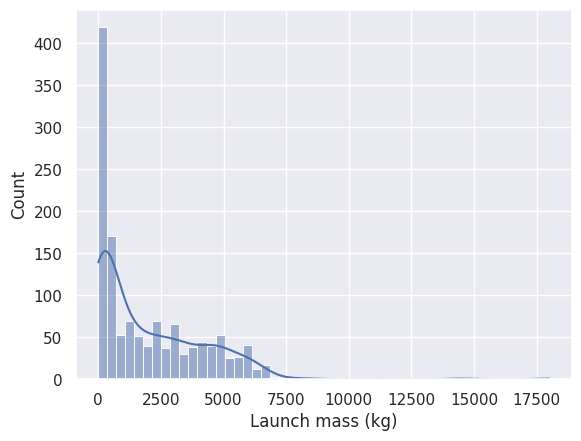

satellites with zero launch mass: 1


In [11]:
ax = sns.histplot(df['launch_mass_kg'], kde=True, bins=50)
ax.set_xlabel('Launch mass (kg)')
plt.savefig('launch_mass_kg_histogram.png', bbox_inches='tight')
plt.show()

print('satellites with zero launch mass:', (df['launch_mass_kg'] == 0).sum())

As predicted from `mean (2007) > median (1200)`: the distribution has a long
right tail of heavy GEO comsats. Subsetting is just the mask idiom from
Class02 — compare USA-operated satellites against the rest:

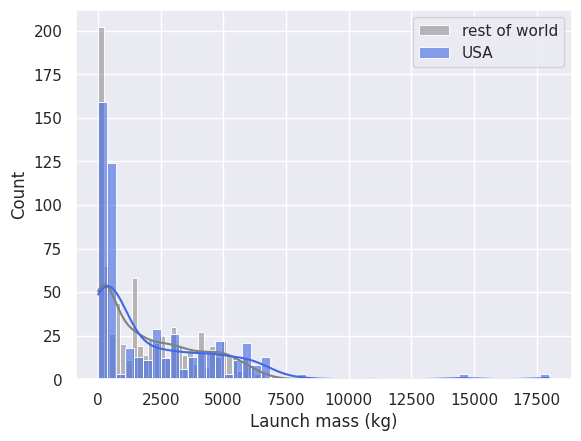

In [12]:
usa = df.loc[df['country_of_operator_owner'] == 'USA', 'launch_mass_kg']
rest = df.loc[df['country_of_operator_owner'] != 'USA', 'launch_mass_kg']

ax = sns.histplot(rest, kde=True, bins=50, label='rest of world', color='grey')
sns.histplot(usa, kde=True, bins=50, label='USA', color='royalblue', alpha=0.6, ax=ax)
ax.set_xlabel('Launch mass (kg)')
ax.legend()
plt.savefig('launch_mass_kg_usa_histogram.png', bbox_inches='tight')
plt.show()

For **categorical** variables, the right plot is a count plot (a bar chart of
frequencies). Who operates satellites, and of which orbit class?

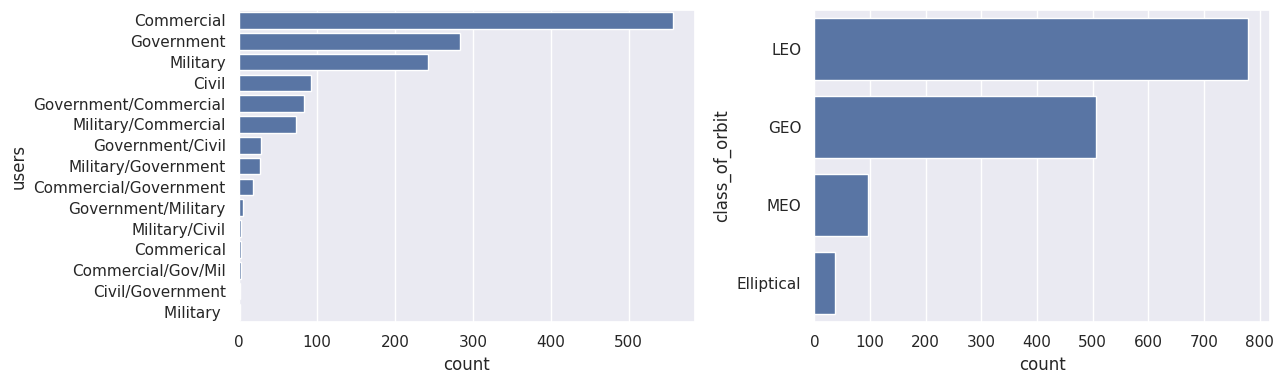

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, y='users', order=df['users'].value_counts().index, ax=axes[0])
sns.countplot(data=df, y='class_of_orbit',
              order=df['class_of_orbit'].value_counts().index, ax=axes[1])
plt.tight_layout()
plt.show()

Horizontal bars (`y=` instead of `x=`) keep long category labels readable.
The dataset is dominated by commercial and government operators, and LEO and
GEO are overwhelmingly the common orbit classes — context that matters if you
later model e.g. satellite lifetime per class.

## Bivariate plots

The natural geometric relationship here is perigee vs apogee. Colouring by
orbit class makes the structure visible at once:

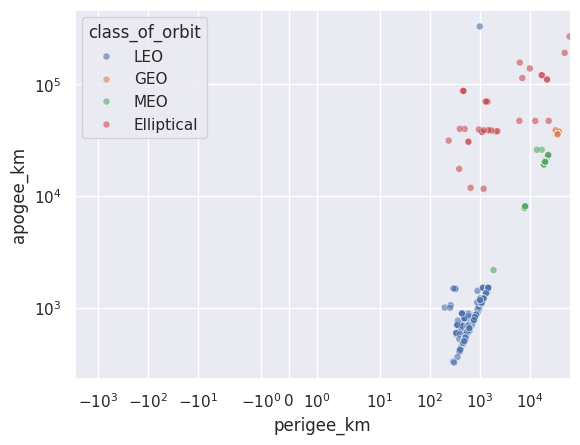

,name_of_satellite_alternate_names,apogee_km,class_of_orbit,purpose
1197,Spektr-R/RadioAstron,330000.0,LEO,Space Science
658,Interstellar Boundary EXplorer (IBEX),268679.0,Elliptical,Space Science


In [14]:
ax = sns.scatterplot(data=df, x='perigee_km', y='apogee_km',
                     hue='class_of_orbit', alpha=0.6, s=25)
ax.set_xscale('symlog')
ax.set_yscale('log')
plt.show()

# Who are those apogee outliers?
df.nlargest(2, 'apogee_km')[['name_of_satellite_alternate_names', 'apogee_km',
                             'class_of_orbit', 'purpose']]

Three lessons in one plot:

1. **Clusters = physics.** GEO satellites sit on a sharp diagonal at
   ~35,786 km (geostationary altitude, where perigee ≈ apogee on circular
   orbits); Elliptical-class satellites fan out below the diagonal.
2. **The cluster only appeared because we coloured by a category.**
   `hue=` is often the single most informative argument you can add.
3. **Outliers aren't always errors.** The 330,000 km apogee is
   *Spektr-R/RadioAstron*, a real space radio-telescope on a highly
   elliptical orbit — deleting it as an "outlier" would have deleted a
   genuine discovery. Investigate before you drop.

## Correlations

A heatmap of the pairwise correlation matrix shows which numeric features
move together:

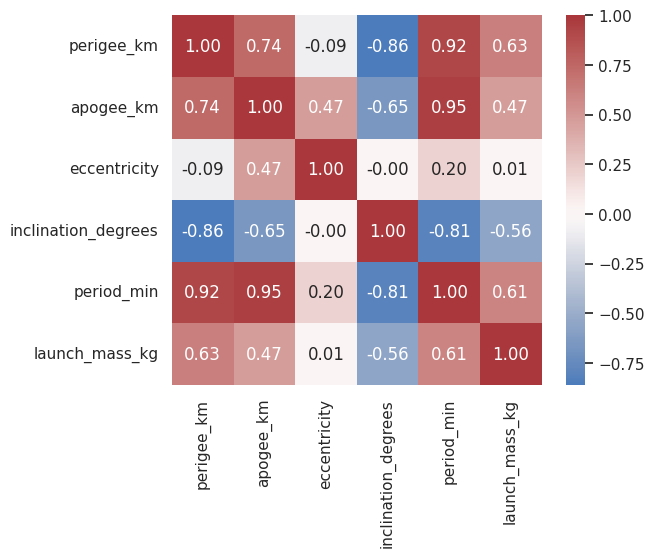

In [15]:
cols = ['perigee_km', 'apogee_km', 'eccentricity', 'inclination_degrees',
        'period_min', 'launch_mass_kg']
corr = df[cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, square=True)
plt.show()

How to read it: `apogee_km ↔ period_min ≈ 1.0` — orbital period is *determined*
by altitude (Kepler's third law), so the correlation is expected physics, not
a coincidence. `apogee_km ↔ eccentricity` is strongly positive: circular
orbits are circular at any height, and elongated orbits reach higher apogees.
Note that `longitude_of_geo_degrees` and identifier-like columns were left
out — correlating IDs is meaningless.

**Correlation ≠ causation ≠ importance.** A heatmap finds *linear, pairwise*
relationships only; non-linear links (like a sine of inclination) won't show
up here, and a feature uncorrelated with the target can still matter inside a
multivariate model.

## The EDA checklist

| Step | Tools | What you catch |
|---|---|---|
| Structure | `head()`, `info()`, `shape` | object-typed numbers, junk columns |
| Quality | `isnull().sum()`, `describe()` | missingness, impossible zeros, extreme outliers |
| Per-variable | `histplot`, `countplot`, `value_counts` | skew, sentinel values, whitespace duplicates, typos |
| Relationships | `scatterplot` (+`hue`), `heatmap` of `corr()` | clusters, expected/nonsense correlations |

For a fully-scripted version of this pipeline (distribution grids, pair
plots, zero-filtered correlations, clustering) see `eda.py` in this folder —
written to be pointed at any target column via the command line.